# MSH 3-T-junction array: Python/kwant exact-diagonalization reference for `msh_tjunctions_tn.ipynb`

kwant model (`build_system_3T`): $-\mu\tau_z + \Delta\tau_x + J\,\mathbf S\cdot\boldsymbol\sigma$ on every site,
`hop_x` $= -t\tau_z + i\alpha\tau_z\sigma_y$, `hop_y` $= -t\tau_z - i\alpha\tau_z\sigma_x$, basis $(c_\uparrow, c_\downarrow, c^\dagger_\downarrow, -c^\dagger_\uparrow)$,
with the geometry and protocols of the Julia/TensorBinding array (`msh_tjunctions_tn.ipynb`), so the two can be compared number for number.
Run `msh_tjunctions_tn.ipynb` first in this directory: it writes the `tb_reference/` matrices used for the Hamiltonian check below.

**Geometry and spin texture.**
* **3 T-junctions** with junction sites at $x_c = -32, 0, 32$.
* **Horizontal chain** $y=0$, $x = -48\dots47$; each cell has 16 sites left of the junction ($x_c-16\dots x_c-1$) and 16 from the junction to the right ($x_c\dots x_c+15$).
* **Vertical legs** $x = x_c$, $y = 1\dots16$ (16 sites), pointing up.
* Chain sites only, no substrate.
* Spin texture as in the Julia code: $\mathbf S = (\cos\phi\sin\theta, \sin\phi\sin\theta, \cos\theta)$, $\theta = (-1)^{x+y}\,\tfrac{\pi}{2} f$,
  $\phi = \theta_{\rm arm} + \pi/2$ with arm angles $0$ (right), $\pi$ (left), $\pi/2$ (up).
  $f = 0$: $\mathbf S\parallel\hat z$ (topological), $f = 1$: in-plane AFM (trivial).
* Protocols: `exchange_12` (Z gate when applied twice), `exchange_23` (X gate when applied twice) and the partial fusion of pair A,
  written for legs of $L_1 = L_2 = 14$ sites and mapped onto the 16-site legs exactly as in the Julia code.

**Analysis** (as in the CZ, QFT and period-finding notebooks, section 6): Majoranas from `individual_MZMs`, fermion modes
$\psi_A$, $\psi_B$ and the full BdG unitary from `fix_unitary`, logical states $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$ as `masks`,
evolution of the full basis with the Gauss–Legendre `step`; leakage of each mode out of the zero-mode subspace; fusion readout $\Delta Q = Q(U|1\rangle) - Q(U|0\rangle)$ from the charge densities $G = W W^\dagger$. Also:
* **Subgap LDOS** (section 5): full diagonalization of $H(f_0)$, total (particle + hole, spin-summed) LDOS
  with Gaussian broadening $\eta = 0.01$; zero-energy LDOS map on the lattice with the initial spin texture.
* **Charge density** $\delta n(x, t) = n_1 - n_0$ along the horizontal chain (section 9), taken from snapshots of the
  same Z and X + fusion evolutions used for the gate analysis (every 5 time units during the gate, every 1 during
  the fusion), so no extra time evolution is needed.

**Contents**
1. Geometry
2. Spin texture and protocols (ported from the Julia code)
3. Hamiltonian
4. Check against the Julia/TensorBinding array (`tb_reference/`)
5. Subgap LDOS and zero-energy map with spins
6. Majoranas, fermion modes and logical states
7. Z gate: exchange_12 twice on junction 1, then partial fusion
8. X gate: exchange_23 twice through junction 2 (rot_Tx = 400), then partial fusion
9. Charge density δn(x, t)
10. Save the leakage and fusion results
11. Cost of the dense route

Figures and `.npz` data are written to `DATA_DIR` (`tjunctions_python_ed_data/`); `tjunctions_compare.ipynb` compares them with
the tensor-network results of `msh_tjunctions_tn.ipynb`. Runtime ≈ 35 min.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")          # tiny matrices: threaded BLAS only adds contention
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
import matplotlib.pyplot as plt
import numpy as np
import kwant
from scipy import linalg as la
from tqdm import trange
import time

plt.rcParams["figure.dpi"] = 144
plt.rcParams["font.size"] = 12

DATA_DIR = "tjunctions_python_ed_data"     # LDOS / δn figures and .npz
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
#pauli matrices
tau_0 = np.array([[1, 0], [0, 1]])
tau_x = np.array([[0, 1], [1, 0]])
tau_y = np.array([[0, -1j], [1j, 0]])
tau_z = np.array([[1, 0], [0, -1]])

#tensor products; used in Hamiltonian function
txs0 = np.kron(tau_x, tau_0)
t0sx = np.kron(tau_0, tau_x)
t0sy = np.kron(tau_0, tau_y)
t0sz = np.kron(tau_0, tau_z)
tzsx = np.kron(tau_z, tau_x)
tzsy = np.kron(tau_z, tau_y)
tzs0 = np.kron(tau_z, tau_0)
tysy = np.kron(tau_y, tau_y)
tysx = np.kron(tau_y, tau_x)   # PHconj, spinor "uddu" (not used here: kwant's spinor is "udd-u")
tys0 = np.kron(tau_y, tau_0)   # PHconj, spinor "udud" (not used here)

## 1. Geometry

`label[(x, y)] = (c, s, n)`: cell $c = 1, 2, 3$, arm $s$ (1 right, 2 left, 3 up), position $n = 0\dots15$ along the arm
(arm 1 starts at the junction site, arm 2 at $x_c - 1$, arm 3 at $y = 1$), the same labels as the Julia `TArray`.

144 sites; x = -48 … 47 ; legs at x = [-32, 0, 32]


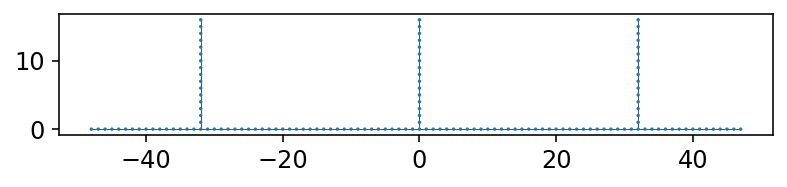

In [3]:
NLEG = 16        # sites per arm (Julia TArray L = 4)
NCELL = 3
SPACING = 2 * NLEG
ARM_ANG = (0.0, np.pi, np.pi / 2)              # right, left, up
ARM_ORIG = ((0, 0), (-1, 0), (0, 1))
ARM_DIR = ((1, 0), (-1, 0), (0, 1))

def center_x(c):
    return int((c - (NCELL + 1) / 2) * SPACING)

def array_pos(c, s, n):
    return (center_x(c) + ARM_ORIG[s-1][0] + n * ARM_DIR[s-1][0],
            ARM_ORIG[s-1][1] + n * ARM_DIR[s-1][1])

label = {array_pos(c, s, n): (c, s, n) for c in range(1, NCELL + 1) for s in (1, 2, 3) for n in range(NLEG)}

def build_system_3T():
    # all sites are chain sites; kwant adds hoppings only between sites that exist
    def chain(site, mu, Delta, J, S):
        Sx, Sy, Sz = S[site.tag]
        JS = J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)
        return -mu * tzs0 + Delta * txs0 + JS

    def hop_x(sitei, sitej, t, alpha):
        return -t * tzs0 + 1j * alpha * tzsy

    def hop_y(sitei, sitej, t, alpha):
        return -t * tzs0 - 1j * alpha * tzsx

    sys = kwant.Builder()
    lat = kwant.lattice.square(norbs=4)
    for (x, y) in label:
        sys[lat(x, y)] = chain
    for delta, hop in zip([(1, 0), (0, 1)], [hop_x, hop_y]):
        sys[kwant.HoppingKind(delta, lat)] = hop
    return sys.finalized()

sys = build_system_3T()
N = len(sys.sites)
tags = [tuple(int(v) for v in site.tag) for site in sys.sites]
xs = np.array([p[0] for p in tags]); ys = np.array([p[1] for p in tags])
print(N, "sites; x =", xs.min(), "…", xs.max(), "; legs at x =", [center_x(c) for c in range(1, NCELL + 1)])
kwant.plot(sys);

## 2. Spin texture and protocols (ported from the Julia code)

`f(c, s, n)` is the rotation fraction (0 topological, 1 trivial). The initial setup has cells 1 and 3 horizontal topological,
cell 2 and every vertical leg trivial, giving 4 MZMs: $\gamma_1,\gamma_2$ at the ends of cell 1's segment, $\gamma_3,\gamma_4$ at cell 3's.

In [4]:
def smoothstep(t):
    return 0.0 if t <= 0 else 1.0 if t >= 1 else np.sin(0.5 * np.pi * t) ** 2

f0 = lambda c, s, n: 1.0 if (c == 2 or s == 3) else 0.0

def spins(f):
    # S[(x, y)] for the texture f(c, s, n);  θ = (−1)^(x+y) (π/2) f,  φ = θ_arm + π/2
    S = {}
    for (x, y), (c, s, n) in label.items():
        th = (-1) ** (x + y) * (np.pi / 2) * f(c, s, n)
        ph = ARM_ANG[s-1] + np.pi / 2
        S[(x, y)] = (np.cos(ph) * np.sin(th), np.sin(ph) * np.sin(th), np.cos(th))
    return S

# ── exchange_12 (L1 = L2 = 14, rot_Tz = 200, step_Tz = 0.1) on cell 1 ──
class Exchange12:
    def __init__(self, L1=14, L2=14, rot_T=200.0, step_T=0.1):
        self.L1, self.L2, self.rot_T, self.step_T = L1, L2, rot_T, step_T
    def duration(self):
        return (self.step_T * (4 * self.L1 + 2 * self.L2 + 8) + 1) * self.rot_T

def f_horizontal_12(p, i, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    if 0 <= i <= L1:
        return ss(tau - s * (i + L1 + L2 + 2)) - ss(tau - s * (L1 - i + 3 * L1 + 2 * L2 + 8))
    if i == L1 + 1:
        return 0.0
    if L1 + 2 <= i <= 2 * L1 + 2:
        return ss(tau - s * (2 * L1 + 2 - i)) - ss(tau - s * (i + L1 + L2 + 2))
    return 1.0

def f_vertical_12(p, k, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    return 1 - ss(tau - s * (k + L1 + 2)) + ss(tau - s * (L2 - k + 3 * L1 + L2 + 5))

def f_braid_12(p, t):
    # arm 1: i = L1 + 1 + n;  arm 2: i = max(L1 − n, 0);  arm 3: k = min(n, L2)
    return lambda s, n: (f_horizontal_12(p, p.L1 + 1 + n, t) if s == 1 else
                         f_horizontal_12(p, max(p.L1 - n, 0), t) if s == 2 else
                         f_vertical_12(p, min(n, p.L2), t))

def f_array_12(p, t):
    fb = f_braid_12(p, t)
    return lambda c, s, n: fb(s, n) if c == 1 else f0(c, s, n)

# ── exchange_23 (rot_Tx = 100, step_Tx = 0.1) through cell 2 ──
class Exchange23:
    def __init__(self, L1=14, L2=14, rot_T=100.0, step_T=0.1):
        self.L1, self.L2, self.rot_T, self.step_T = L1, L2, rot_T, step_T
    def duration(self):
        return (self.step_T * (self.L1 + 3 * self.L2 + 2 * self.L1 + 3) + 1) * self.rot_T

def f_h23(p, i, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    if 2 * L1 + 3 <= i <= 3 * L1 + 3:
        return 1 - ss(tau - s * (i - 2 * L1 - 3)) + ss(tau - s * (4 * L1 + 4 - i + L2 + L1 + 2))
    if 3 * L1 + 4 <= i <= 4 * L1 + 4:
        return 1 - ss(tau - s * (4 * L1 + 4 - i + L2 + L1 + 1)) + ss(tau - s * (i - 3 * L1 - 4 + 3 * L2 + 2 * L1 + 3))
    raise ValueError(f"i = {i} outside junction 2's segment")

def f_v23(p, k, t):
    tau, s = t / p.rot_T, p.step_T
    ss = smoothstep
    return 1 - ss(tau - s * (k + p.L1 + 2)) + ss(tau - s * (p.L2 - k + 3 * p.L1 + p.L2 + 5))

def f_array_23(p, t):
    # cell 2: right arm i = 3L1 + 3 + n; left arm (16 sites) mapped linearly onto i = 3L1 + 2 … 2L1 + 3; up k = min(n, L2)
    def f(c, s, n):
        if c != 2:
            return f0(c, s, n)
        if s == 1:
            return f_h23(p, 3 * p.L1 + 3 + n, t)
        if s == 2:
            return f_h23(p, (3 * p.L1 + 2) - (p.L1 - 1) * n / (p.L1 + 1), t)
        return f_v23(p, min(n, p.L2), t)
    return f

# ── partial fusion of pair A on cell 1 (rot_T0 = 100, step_T0 = 0.2, Lp = 1) ──
class Fusion:
    def __init__(self, L1=14, Lp=1, rot_T=100.0, step_T=0.2):
        self.L1, self.Lp, self.rot_T, self.step_T = L1, Lp, rot_T, step_T
    def duration(self):
        return ((self.L1 - self.Lp + 1) * self.step_T + 1) * self.rot_T

def f_fuse(q, t):
    tau = t / q.rot_T
    def f(c, s, n):
        if c != 1:
            return f0(c, s, n)
        if s == 3:
            return 1.0
        if s == 2 and n < q.Lp:
            return 0.0
        if s == 1 and n <= q.Lp:
            return 0.0
        return smoothstep(tau - q.step_T * (NLEG - 1 - n))     # outer end first
    return f

## 3. Hamiltonian

`ham_kwant(f)` is the full kwant matrix. For time evolution, $H(t) = H_{J=0} + J\sum_{\rm chain}\tau_0\otimes\mathbf S\cdot\boldsymbol\sigma$
is assembled from the $J = 0$ kwant matrix and the exchange blocks, which is identical and much faster (checked below).

In [5]:
params = dict(t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8)

def ham_kwant(f, **kw):
    p = {**params, **kw, "S": spins(f)}
    return sys.hamiltonian_submatrix(params=p)

H_noJ = ham_kwant(f0, J=0.0)

def exchange_matrix(f, J=params["J"]):
    S = spins(f)
    H = np.zeros((4 * N, 4 * N), complex)
    for k, p in enumerate(tags):
        Sx, Sy, Sz = S[p]
        H[4*k:4*k+4, 4*k:4*k+4] = J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)
    return H

def ham(f):
    return H_noJ + exchange_matrix(f)

def Cop(v):
    # particle–hole conjugation in the (u↑, u↓, v↓, −v↑) basis:  C = τ_y σ_y K  (C H* C = −H)
    return (np.kron(np.eye(N), tysy) @ v.conj())

H0 = ham(f0)
print("‖H_fast − H_kwant‖ =", la.norm(H0 - ham_kwant(f0)),
      "  Hermitian:", la.norm(H0 - H0.conj().T),
      "  PH: ‖C H* C + H‖ =", la.norm(np.kron(np.eye(N), tysy) @ H0.conj() @ np.kron(np.eye(N), tysy) + H0))

‖H_fast − H_kwant‖ = 0.0   Hermitian: 0.0   PH: ‖C H* C + H‖ = 0.0


## 4. Check against the Julia/TensorBinding array

`tb_reference/*.bin` are dense BdG matrices written by `export_tb_reference` in `msh_tjunctions_tn.ipynb` (section 4) (basis $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$,
order nambu ⊗ spin ⊗ site, sites listed in `coords.txt`). Per site, the Julia basis is $W$ times the kwant one:
$(u_\uparrow, u_\downarrow, v_\uparrow, v_\downarrow) = (a, b, -d, c)$ for kwant components $(a, b, c, d) = (u_\uparrow, u_\downarrow, v_\downarrow, -v_\uparrow)$.

In [6]:
ref_dir = "tb_reference"
if not os.path.isfile(os.path.join(ref_dir, "coords.txt")):
    raise FileNotFoundError(f"{ref_dir}/ not found: run msh_tjunctions_tn.ipynb in this directory first (section 4 writes it)")
coords = [tuple(map(int, l.split())) for l in open(os.path.join(ref_dir, "coords.txt"))]
Wsite = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, -1], [0, 0, 1, 0]])
kpos = {p: k for k, p in enumerate(tags)}
P = np.zeros((4 * N, 4 * N))            # kwant (site-major) → Julia (nambu ⊗ spin ⊗ site)
for j, p in enumerate(coords):
    k = kpos[p]
    for b in range(4):                  # Julia component b = (nambu, spin)
        for a in range(4):
            P[b * N + j, 4 * k + a] = Wsite[b, a]

def to_tb_basis(H):
    return P @ H @ P.T

checks = {"initial": f0,
          "z_t1020": f_array_12(Exchange12(), 1020.0),
          "x100_t485": f_array_23(Exchange23(rot_T=100.0), 485.0),
          "fuse_t300": f_fuse(Fusion(), 300.0)}
for name, f in checks.items():
    Href = np.fromfile(os.path.join(ref_dir, name + ".bin"), dtype=np.complex128).reshape(4 * N, 4 * N, order="F")
    print(f"{name:10s}  ‖H_kwant − H_TensorBinding‖ = {la.norm(to_tb_basis(ham_kwant(f)) - Href):.1e}")

initial     ‖H_kwant − H_TensorBinding‖ = 3.5e-12
z_t1020     ‖H_kwant − H_TensorBinding‖ = 4.3e-10
x100_t485   ‖H_kwant − H_TensorBinding‖ = 2.0e-09
fuse_t300   ‖H_kwant − H_TensorBinding‖ = 1.9e-11


## 5. Subgap LDOS and zero-energy map with spins

$A(\mathbf r, \omega) = \sum_k w_k(\mathbf r)\, g_\eta(\omega - E_k)$, where $w_k$ sums $|U|^2$ over the four orbitals of
each site and $g_\eta$ is a Gaussian with $\eta = 0.01$, on $\omega \in [-0.2, 0.2]$ (401 points). All eigenstates are
included: those at $|E| \ge 0.268$ contribute less than $e^{-23}$ inside the window.
Spins are drawn as in-plane $(S_x, S_y)$ arrows and $\hat z$ spins as dots.

lowest |E| (one per ± pair): [0.     0.     0.127  0.2683] ; max A(r, 0) = 15.21


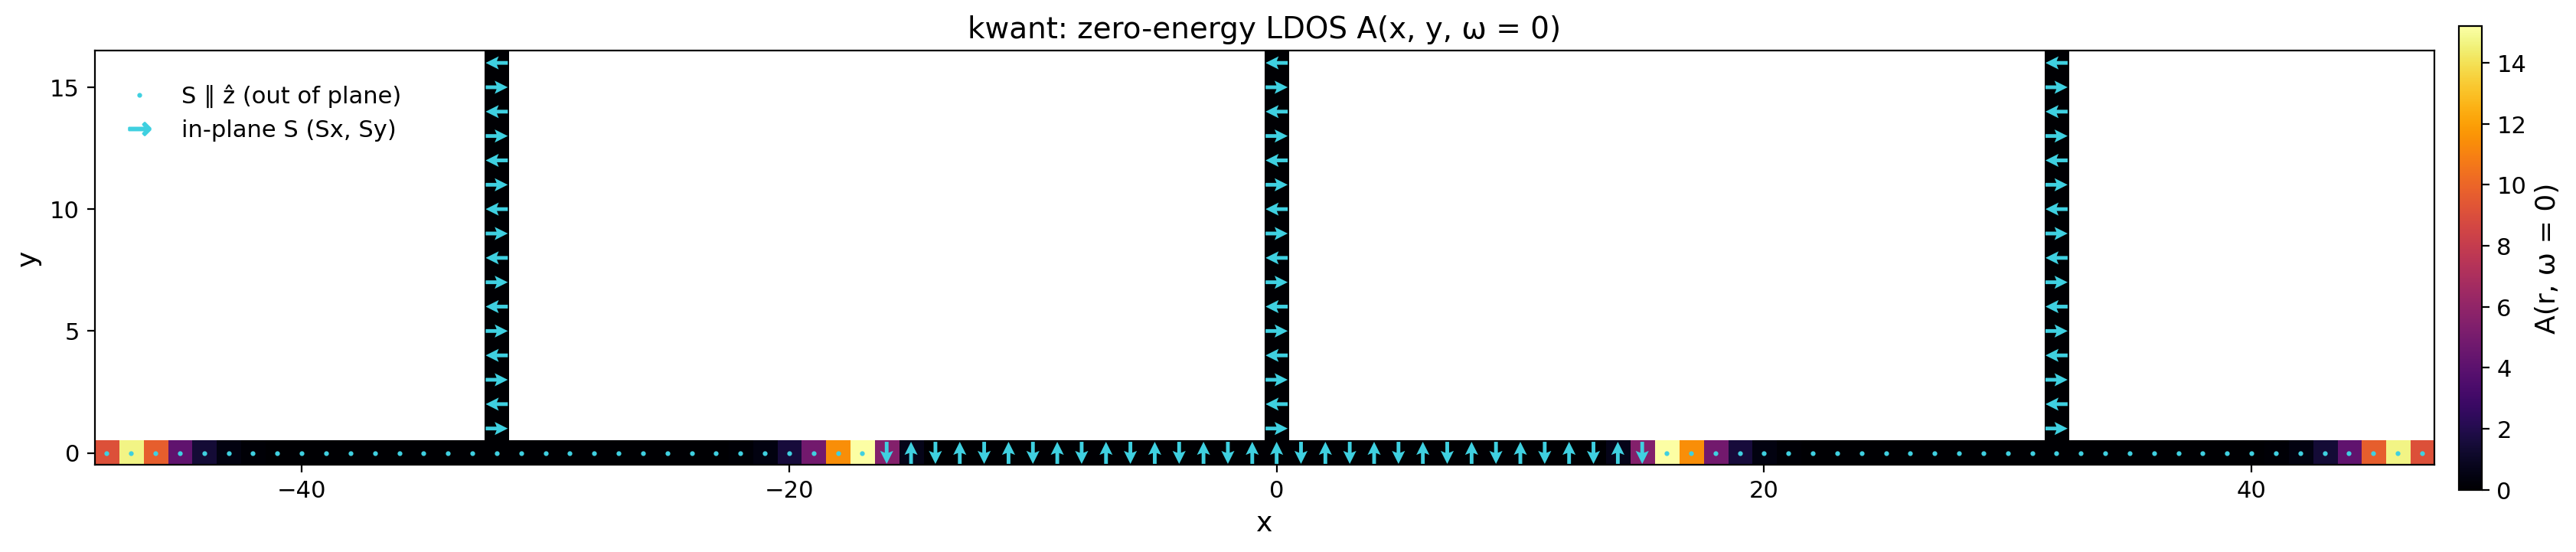

In [7]:
eta = 0.01
omega = np.linspace(-0.2, 0.2, 401)
E_all, U_all = la.eigh(H0)
w_site = (np.abs(U_all) ** 2).reshape(N, 4, -1).sum(axis=1)                    # (site, state)
g_eta = np.exp(-(omega[None, :] - E_all[:, None]) ** 2 / (2 * eta ** 2)) / (np.sqrt(2 * np.pi) * eta)
A_ldos = w_site @ g_eta                                                          # (site, ω)
j0 = np.argmin(np.abs(omega))
print("lowest |E| (one per ± pair):", np.round(np.sort(np.abs(E_all))[:8:2], 4),
      "; max A(r, 0) =", round(A_ldos[:, j0].max(), 2))

S0 = spins(f0); Sx0, Sy0, Sz0 = (np.array([S0[p][k] for p in tags]) for k in range(3))

def ldos_figure(Amat, name, out, vmax):
    x0, y0 = xs.min(), ys.min()
    grid = np.full((ys.max() - y0 + 1, xs.max() - x0 + 1), np.nan)
    grid[ys - y0, xs - x0] = Amat[:, j0]
    fig, ax = plt.subplots(figsize=(17.04, 3.6), dpi=200)
    im = ax.imshow(np.ma.masked_invalid(grid), origin="lower", cmap="inferno", vmin=0, vmax=vmax,
                   extent=(x0 - 0.5, xs.max() + 0.5, y0 - 0.5, ys.max() + 0.5), interpolation="nearest")
    ax.set_facecolor("white")
    inpl = np.hypot(Sx0, Sy0) > 0.5
    ax.quiver(xs[inpl], ys[inpl], Sx0[inpl], Sy0[inpl], color="#3FD0E0", angles="xy", scale_units="xy", scale=1.1,
              pivot="mid", width=0.0016, headwidth=3.5, headlength=3.5, headaxislength=3)
    ax.plot(xs[~inpl], ys[~inpl], ".", color="#3FD0E0", ms=2.5, label="S ∥ ẑ (out of plane)")
    ax.plot([], [], marker=r"$\rightarrow$", ls="", color="#3FD0E0", ms=10, label="in-plane S (Sx, Sy)")
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.97), fontsize=11, frameon=False)
    ax.set(xlabel="x", ylabel="y", title=f"{name}: zero-energy LDOS A(x, y, ω = 0)")
    ax.set_aspect("equal"); ax.set_yticks([0, 5, 10, 15])
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("A(r, ω = 0)", size=13)
    cb.ax.tick_params(labelsize=11)
    ax.title.set_size(14); ax.xaxis.label.set_size(13); ax.yaxis.label.set_size(13); ax.tick_params(labelsize=11)
    fig.tight_layout(); fig.savefig(out, bbox_inches="tight"); plt.show(); plt.close(fig)

np.savez(os.path.join(DATA_DIR, "array_ldos_kwant.npz"), x=xs, y=ys, omega=omega, A=A_ldos)
ldos_figure(A_ldos, "kwant", os.path.join(DATA_DIR, "array_ldos_kwant.png"), A_ldos[:, j0].max())

## 6. Majoranas, fermion modes and logical states

The same construction as the CZ, QFT and period-finding notebooks (`dag`, `PHconj`, `takagi`, `individual_MZMs`, `fix_unitary`, the
logical-state `masks` and the Gauss–Legendre `step`):
1. Diagonalize $H(f_0)$. `individual_MZMs` takes the zero-energy subspace ($|E| < 10^{-3}$: the four MZMs), makes its states eigenstates of
   $C$ (Takagi factorization) and localizes them with the position operator.
2. Pair the Majoranas (`mbs2`): $(\gamma_1, \gamma_2)$ at the ends of junction 1's segment and $(\gamma_3, \gamma_4)$ at junction 3. `fix_unitary`
   writes the fermions into the full $4N \times 4N$ BdG unitary `U_fixed`: $\psi_A$, $\psi_B$ in columns $2N$, $2N+1$ (positive energy) and their
   particle–hole partners in columns $2N-1$, $2N-2$.
3. Logical states as `masks` over the columns: $|n_A n_B\rangle$ fills the negative-energy bulk, the occupied modes and the partners of the
   empty ones. The logical qubit is the even-parity pair $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$.
4. Evolve the full basis with the 2-stage Gauss–Legendre `step` (4th order, $H$ at the two Gauss points), here in the sparse-LU form of the
   period-finding notebook, with $dt = 0.25$; the columns are renormalized after each step.
5. Read out at every snapshot: the charge density of each logical state from $G = W W^\dagger$ of its occupied columns (electron
   components), so $\delta n(\mathbf r, t) = n(\hat U|11\rangle) - n(\hat U|00\rangle)$ and $\Delta Q(t) = \sum_{\mathbf r}\delta n$; and the overlap of $\psi_A$, $\psi_B$
   (columns $2N$, $2N+1$) with the initial zero-mode subspace, whose deficit is the leakage of each mode out of it.

**One change for this geometry.** `individual_MZMs` localizes with `x = np.tile(range(N//4), 4)`, the site index; for the site-major
ordering `4*site + c` this should be `np.repeat`, and here the site index is not ordered along the chain, so the operator uses the $x$
coordinate of each site.


In [8]:
import warnings
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from concurrent.futures import ThreadPoolExecutor

def dag(A, axis1=-2, axis2=-1):
    """Return Hermitian conjugate."""
    if A.ndim > 1:
        return A.swapaxes(axis1, axis2).conj()
    else:
        return A.conj()


def PHconj(psi, ordering="ltslts", spinor="udd-u"):
    """Return the particle-hole conjugate C psi = (tau_y sigma_y) psi^* for the kwant spinor "udd-u".

    The other branches cover the spinor orderings "uddu" (tau_y sigma_x) and "udud" (tau_y sigma_0), and a
    Nambu-outer ordering "tsltsl"; this notebook uses only the default."""
    N, n = psi.shape
    if ordering == "ltslts" and spinor == "udd-u":
        return (tysy @ psi.reshape(N // 4, 4, n).conj()).reshape(N, n)
    elif ordering == "ltslts" and spinor == "uddu":
        return (tysx @ psi.reshape(N // 4, 4, n).conj()).reshape(N, n)
    elif ordering == "ltslts" and spinor == "udud":
        return (tys0 @ psi.reshape(N // 4, 4, n).conj()).reshape(N, n)
    elif ordering == "tsltsl" and spinor == "udd-u":
        tysyb = np.kron(tysy, np.eye(N//4))
        return (tysyb @ psi.conj())


def takagi(A):
    """D, U = takagi(A)

    Diagonalize a complex symmetric matrix as A = U D U^T
    where U is unitary and D is diagonal."""
    # B is Hermitian positive semi-definite
    B = dag(A) @ A
    b, V = np.linalg.eigh(B)
    # C is complex symmetric with C=X+iY, [X,Y]=0
    C = V.T @ A @ V
    X = C.real
    Y = C.imag
    # C^dag C = V^dag A^dag A V = diag(b) is real, and C^dag C = X^2 + Y^2 + i[X, Y], so [X, Y] = 0: X and Y
    # are real symmetric and commute, and one real orthogonal W diagonalizes both (eigenvectors of X + Y,
    # assuming X + Y has no accidental degeneracy). Then U^T A U = W^T C W = diag(z).
    # Simultaneously diagonalize X and Y
    w, W = np.linalg.eigh(X + Y)
    U = V @ W
    # z_i = r_i e^{i\theta_i} = [U^T A U]_{ii}
    z = np.sum(U * (A @ U), axis=0)
    r = np.abs(z)
    # Multiply by e^{-i\theta_i/2}
    U *= (r / z) ** 0.5
    # Now U^T A U = diag(r), i.e. A = U^* diag(r) U^dag: the Takagi factor in A = Z D Z^T is Z = U^*
    return r, U.conj()


def individual_MZMs(E, M, tol=1e-3, ordering="ltslts", spinor="udd-u"):
    """Fix the unitary M in place.

    Fix M so that the form
    M = [[U, V^*],
         [V, U^*]]
    is unitary
    First step: separate MZMs.

    Parameters
    ----------
    E : ndarray
        Eigenvalues.
    M : ndarray
        Eigenvectors.
    tol : float
        Max energy of zero-energy subspace.

    Returns
    -------
    mbs : ndarray
        wavefunctions with individual MZMs
    mask : ndarray
        mask pointing to zero-energy subspace
    M : ndarray
        eigenvectors

    """

    # Get zero-energy subspace
    mask = np.abs(E) < tol
    # Expand range if #states is odd
    if sum(mask) % 2 == 1:
        # Index of smallest energy outside of subspace
        ind = np.ma.array(np.abs(E), mask=mask).argmin()
        # Add index to subspace
        mask[ind] = True
        warnings.warn(f"Adding E={E[ind]} to zero-energy subspace.")

    psi = M[:, mask]
    N, n = psi.shape
    # Get Majoranas (eigenstates of C)
    # C_ij = <psi_i|C psi_j> is complex symmetric. With C = Z D Z^T (Takagi) and gamma = psi Z:
    # C gamma = (C psi) Z^* = psi C Z^* = psi Z D Z^T Z^* = gamma D, since Z^T Z^* = (Z^dag Z)^* = 1.
    # D = 1 when the subspace is closed under C, so every column of gamma is a Majorana.
    C = dag(psi) @ PHconj(psi, ordering=ordering, spinor=spinor)
    c, Z = takagi(C)
    gamma = psi @ Z

    # Localize Majoranas
    x = np.repeat(xs, 4)   # x coordinate of each component (site-major ordering, see the markdown)
    R = dag(gamma) * x @ gamma
    # R is real for Majoranas (C commutes with x), so O is real orthogonal and gamma O stays self-conjugate
    r, O = np.linalg.eigh(R.real)  # Want O ortho to conserve C
    mbs = gamma @ O

    return mbs, mask, M


def fix_unitary(mbs, mask, M):
    """Fix the unitary M in place.

    Fix M so that the form
    M = [[U, V^*],
         [V, U^*]]
    is unitary.
    second step: pair up MZMs, after manual reordering so that MZMs that you want paired are 0-1, 2-3, 4-5 etc. in the second axis of mbvs

    Parameters
    ----------
    mbs : ndarray
        wavefunctions with individual MZMs
    mask : ndarray
        mask pointing to zero-energy subspace
    M : ndarray
        eigenvectors

    Returns
    -------
    M: ndarray
        fixed unitary

    """
    N, n = mbs.shape
    # Majorana to fermion: (gamma_2k, gamma_2k+1) -> phi_k = (gamma_2k + i gamma_2k+1)/sqrt2 and C phi_k
    U = np.array([[1, 1], [1j, -1j]]) / 2**0.5
    phi = mbs @ np.kron(np.eye(n // 2), U)
    # Reorder I x tau_x -> tau_x x I: [phi_0, Cphi_0, phi_1, Cphi_1, ...] -> [phi_0, phi_1, ..., Cphi_0, Cphi_1, ...]
    ind = np.arange(n).reshape(n // 2, 2).swapaxes(0, 1).ravel()
    phi = phi[:, ind]

    # Reorder phi_{-n} = C phi_n: reverse the first half, [phi_(n/2-1), ..., phi_0, Cphi_0, ..., Cphi_(n/2-1)].
    # In the eigh ordering of a BdG matrix, column 2N+k (k-th state above zero) and column 2N-1-k (k-th below)
    # are C partners. With this order, column 2N-1-k holds phi_k and column 2N+k holds C phi_k, so the fixed M
    # keeps that mirror structure about the middle. For n = 2 the reversal does nothing.
    ind = np.arange(n).reshape(2, n // 2)
    ind[0] = np.flip(ind[0])
    ind = ind.ravel()
    phi = phi[:, ind]
    # Overwrite with corrected states
    M[:, mask] = phi

    return M


# ── Majoranas, fermion modes and the fixed unitary ──
E0, U0 = np.linalg.eigh(H0)
mbs, mask, U0 = individual_MZMs(E0, U0, tol=1e-3, ordering="ltslts", spinor="udd-u")
print("zero-energy subspace:", mask.sum(), "states;  Majorana centres x =",
      np.round([np.real(np.vdot(g, np.repeat(xs, 4) * g)) for g in mbs.T], 1))

# pair up Majoranas: (γ1 γ2) = ψ_A at junction 1, (γ3 γ4) = ψ_B at junction 3
mbs2 = mbs[:, [0, 1, 2, 3]]
U_fixed = fix_unitary(mbs2, mask, U0)
psi0 = U_fixed.copy()
E_cols = np.real(np.einsum("ij,ik,kj->j", psi0.conj(), H0, psi0))
print("energies of columns 2N−2 … 2N+1:", E_cols[2*N-2:2*N+2])
assert np.all(E_cols[2*N:2*N+2] > 0), "negative energies must come first: swap the order within that pair in mbs2"
print(f"‖U_fixed† U_fixed − 1‖ = {la.norm(psi0.conj().T @ psi0 - np.eye(4*N)):.1e},  max ‖Cψ_(2N+k) − ψ_(2N−1−k)‖ = "
      f"{max(la.norm(Cop(psi0[:, 2*N+k]) - psi0[:, 2*N-1-k]) for k in range(2)):.1e}")

# ── logical states ──
n_states = 4
masks = np.zeros((n_states, 4*N), bool)      # excited states empty
masks[0, 2*N:2*N+2] = (0, 0)                 # |00> = |0>_L
masks[1, 2*N:2*N+2] = (0, 1)                 # |01>
masks[2, 2*N:2*N+2] = (1, 0)                 # |10>
masks[3, 2*N:2*N+2] = (1, 1)                 # |11> = |1>_L
masks[:, :2*N] = np.flip(~masks[:, 2*N:], axis=1)   # if a mode is occupied, its particle-hole partner is empty
Z0 = psi0[:, 2*N-2:2*N+2]                    # initial zero-mode subspace

# ── sparse H(t) and the 2-stage Gauss–Legendre step (sparse LU, as in the period-finding notebook) ──
H_noJ_sp = sp.csc_matrix(H_noJ)
def exchange_sparse(f, J=params["J"]):
    S = spins(f)
    return sp.block_diag([J * (S[p][0] * t0sx + S[p][1] * t0sy + S[p][2] * t0sz) for p in tags], format="csc")
def ham_sp(f):
    return (H_noJ_sp + exchange_sparse(f)).tocsc()

I_sp = sp.identity(4*N, dtype=complex, format="csc")
c1, c2 = 0.5 - 3**0.5/6, 0.5 + 3**0.5/6
a12, a21 = 0.25 - 3**0.5/6, 0.25 + 3**0.5/6
n_threads = 1      # threads for the sparse solve; 1 keeps the timings of section 11 single-thread (more is faster)
_pool = ThreadPoolExecutor(n_threads)
DT = 0.25

def step(psi, t, dt, ft):
    M0 = -1j * ham_sp(ft(t + c1*dt))
    M1 = -1j * ham_sp(ft(t + c2*dt))
    A = sp.bmat([[I_sp - 0.25*dt*M0, -a12*dt*M0],
                 [-a21*dt*M1, I_sp - 0.25*dt*M1]], format="csc")
    B = np.vstack([M0 @ psi, M1 @ psi])
    lu = splu(A, permc_spec="MMD_AT_PLUS_A")
    chunks = np.array_split(np.arange(B.shape[1]), n_threads)
    K = np.hstack(list(_pool.map(lambda c: lu.solve(np.ascontiguousarray(B[:, c])), chunks)))
    K = K.reshape(2, *psi.shape)
    return psi + 0.5*dt*(K[0] + K[1])

# ── readout ──
hz = np.where(ys == 0)[0]; hz = hz[np.argsort(xs[hz])]               # horizontal chain, left to right
tauz = np.tile([1, 1, -1, -1], N)

def electron_density(W):
    """Electron number per site of the state with occupied columns W: electron part of diag(G), G = W W†."""
    return (np.abs(W) ** 2).sum(axis=1).reshape(N, 4)[:, :2].sum(axis=1)

def readout(psi):
    """δn = n(|11>) − n(|00>) on the horizontal chain, ΔQ and its two modes, and the overlaps of ψ_A, ψ_B with the initial zero modes."""
    dn = electron_density(psi[:, masks[3]]) - electron_density(psi[:, masks[0]])
    dq_modes = [np.real(np.vdot(psi[:, 2*N+k], tauz * psi[:, 2*N+k])) for k in range(2)]
    return dict(dn_h=dn[hz], dQ=dn.sum(), dQ_modes=dq_modes, z=Z0.conj().T @ psi[:, 2*N:2*N+2])

def evolve(ft, psi, t0, t1, dt_snap, dt=DT):
    """Full-basis evolution t0 → t1; readout at t0 and every dt_snap."""
    nsteps = int(round((t1 - t0) / dt)); every = int(round(dt_snap / dt))
    ts, R = [t0], [readout(psi)]
    for k in trange(1, nsteps + 1, mininterval=10):
        psi = step(psi, t0 + (k - 1) * dt, dt, ft)
        psi = psi / np.linalg.norm(psi, axis=0)
        if k % every == 0 or k == nsteps:
            ts.append(t0 + k * dt); R.append(readout(psi))
    return psi, np.array(ts), R

def mode_leak(R, name):
    """Leakage of ψ_A, ψ_B out of the initial zero-mode subspace at the last snapshot."""
    z = R[-1]["z"]; lk = [1 - la.norm(z[:, k]) ** 2 for k in range(2)]
    print(f"── {name}: leak (ψ_A, ψ_B) = {np.round(lk, 9)}")
    return lk

def dQ_adiabatic(H):
    E, U = la.eigh(H); o = np.argsort(np.abs(E))[:4]
    return sum(0.0 if abs(E[i]) < 1e-11 else np.real(np.vdot(U[:, i], tauz * U[:, i])) for i in o if E[i] > 0)

q = Fusion(); Tf = q.duration()
HT_end = ham(f_fuse(q, Tf))                               # the same final Hamiltonian for every run
E_end, U_end = la.eigh(HT_end); Z4_end = U_end[:, np.argsort(np.abs(E_end))[:4]]
TIMES = {}                                                # wall time (s) of each evolution

def run(ft, T1, label, dt_gate=5.0, dt_fuse=1.0):
    """Gate (two exchanges of duration T1, or none) and then the partial fusion; returns the readout and the leakage."""
    Tg = 2 * T1; out = dict(Tg=Tg); psi = psi0.copy(); ts, R = np.array([0.0]), [readout(psi0)]
    if T1 > 0:
        t_ = time.perf_counter()
        psi, t1s, R1 = evolve(ft, psi, 0.0, T1, dt_gate)
        out["leak_one"] = mode_leak(R1, f"{label}: one exchange")
        psi, t2s, R2 = evolve(ft, psi, T1, Tg, dt_gate)
        out["leak"] = mode_leak(R2, f"{label}: two exchanges")
        ts, R = np.concatenate([t1s, t2s[1:]]), R1 + R2[1:]
        TIMES[f"{label}_gate"] = time.perf_counter() - t_
    t_ = time.perf_counter()
    psi, tf, Rf = evolve(ft, psi, Tg, Tg + Tf, dt_fuse)
    TIMES[f"{label}_fusion"] = time.perf_counter() - t_
    ts, R = np.concatenate([ts, tf[1:]]), R + Rf[1:]
    lk = [1 - la.norm(Z4_end.conj().T @ psi[:, 2*N+k]) ** 2 for k in range(2)]
    out["fusion"] = dict(dQ=Rf[-1]["dQ"], dQ_modes=Rf[-1]["dQ_modes"], leak=lk, ts=tf - Tg, dQ_t=np.array([r["dQ"] for r in Rf]),
                         dQad_t=np.array([dQ_adiabatic(ham(ft(t))) for t in tf]))
    out["snap"] = (ts, np.array([r["dn_h"] for r in R]), np.array([r["dQ"] for r in R]))
    print(f"   fusion: ΔQ = {out['fusion']['dQ']:+.6f} (ψ_A {out['fusion']['dQ_modes'][0]:+.6f}, ψ_B {out['fusion']['dQ_modes'][1]:+.1e}),"
          f" leak {np.round(lk, 9)}")
    return out

zero-energy subspace: 4 states;  Majorana centres x = [-46.6 -17.5  16.5  45.6]
energies of columns 2N−2 … 2N+1: [-1.15785960e-09 -1.09010713e-09  1.09010708e-09  1.15785960e-09]
‖U_fixed† U_fixed − 1‖ = 6.5e-14,  max ‖Cψ_(2N+k) − ψ_(2N−1−k)‖ = 2.2e-14


## 7. Z gate: exchange_12 twice on junction 1, then partial fusion

One exchange_12 is $\sqrt{Z}$; two make Z. Then the partial fusion of pair A reads out the logical state as a charge difference; a run of
the fusion alone (no gate) is the control. Snapshots every 5 time units during the gate and every 1 during the fusion.

In [9]:
p12 = Exchange12(); T12 = p12.duration()
fz = lambda t: (f_array_12(p12, t) if t < T12 else f_array_12(p12, t - T12) if t < 2 * T12 else f_fuse(q, t - 2 * T12))
print("‖H(2T12) − H(0)‖ =", la.norm(ham(fz(2 * T12 - 1e-9)) - H0), "; T12 =", T12)
rZ = run(fz, T12, "Z")
ff = lambda t: f_fuse(q, t)                              # control: fusion with no gate
rF = run(ff, 0.0, "F")

‖H(2T12) − H(0)‖ = 0.0 ; T12 = 2040.0000000000002


100%|██████████| 8160/8160 [04:42<00:00, 28.92it/s]


── Z: one exchange: leak (ψ_A, ψ_B) = [ 9.74e-07 -0.00e+00]


100%|██████████| 8160/8160 [04:48<00:00, 28.30it/s]


── Z: two exchanges: leak (ψ_A, ψ_B) = [ 1.997e-06 -0.000e+00]


100%|██████████| 1520/1520 [00:54<00:00, 27.96it/s]


   fusion: ΔQ = -0.477717 (ψ_A -0.477717, ψ_B +3.8e-08), leak [ 3.6963e-05 -0.0000e+00]


100%|██████████| 1520/1520 [00:54<00:00, 28.13it/s]


   fusion: ΔQ = -0.477373 (ψ_A -0.477373, ψ_B +3.8e-08), leak [ 3.7778e-05 -0.0000e+00]


## 8. X gate: exchange_23 twice through junction 2 (rot_Tx = 400), then partial fusion

In [10]:
p23 = Exchange23(rot_T=400.0); T23 = p23.duration()
fx = lambda t: (f_array_23(p23, t) if t < T23 else f_array_23(p23, t - T23) if t < 2 * T23 else f_fuse(q, t - 2 * T23))
rX = run(fx, T23, "X400")

100%|██████████| 15520/15520 [09:15<00:00, 27.95it/s]


── X400: one exchange: leak (ψ_A, ψ_B) = [3.4886e-05 1.2400e-07]


100%|██████████| 15520/15520 [09:14<00:00, 27.97it/s]


── X400: two exchanges: leak (ψ_A, ψ_B) = [3.4163e-05 3.4869e-05]


100%|██████████| 1520/1520 [00:54<00:00, 28.12it/s]


   fusion: ΔQ = +0.477004 (ψ_A +0.476113, ψ_B +8.9e-04), leak [8.0751e-05 3.3308e-05]


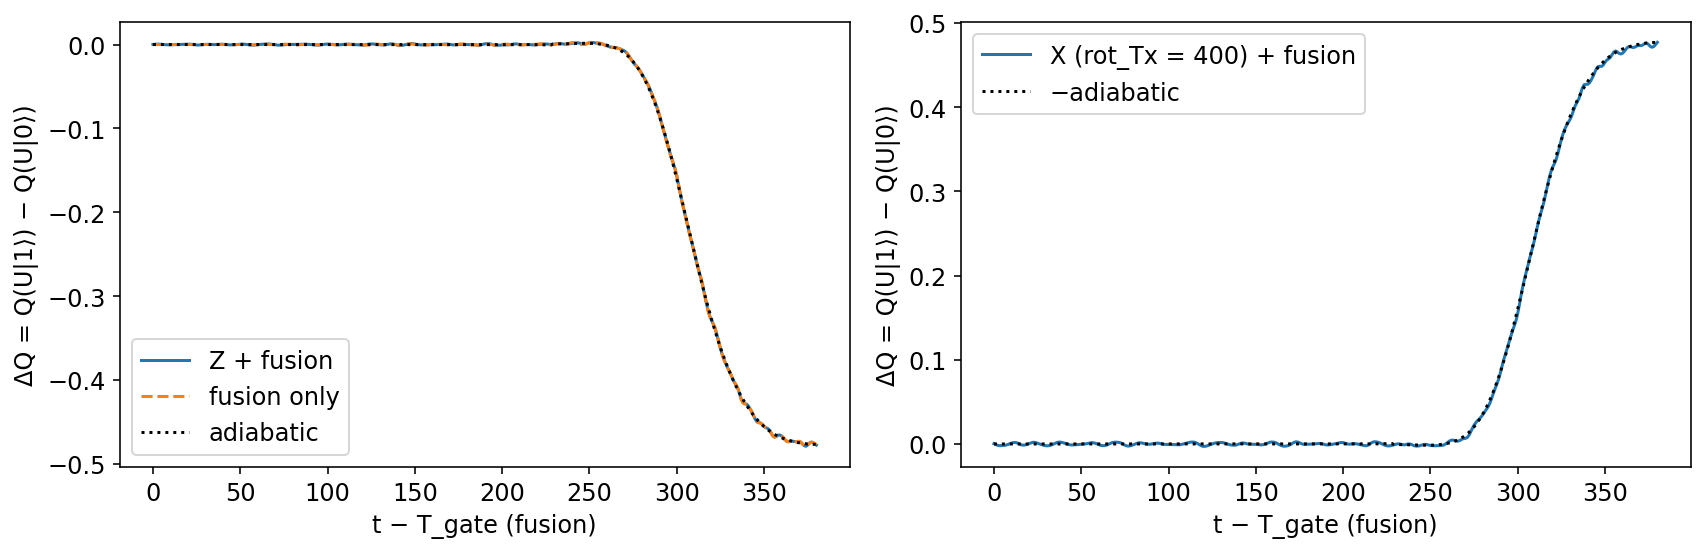

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r, lbl, ls in ((rZ, "Z + fusion", "-"), (rF, "fusion only", "--")):
    ax[0].plot(r["fusion"]["ts"], r["fusion"]["dQ_t"], ls, label=lbl)
ax[0].plot(rF["fusion"]["ts"], rF["fusion"]["dQad_t"], "k:", label="adiabatic")
ax[1].plot(rX["fusion"]["ts"], rX["fusion"]["dQ_t"], label="X (rot_Tx = 400) + fusion")
ax[1].plot(rF["fusion"]["ts"], -rF["fusion"]["dQad_t"], "k:", label="−adiabatic")
for a in ax:
    a.set_xlabel("t − T_gate (fusion)"); a.set_ylabel("ΔQ = Q(U|1⟩) − Q(U|0⟩)"); a.legend()
plt.tight_layout()

## 9. Charge density δn(x, t) = n₁ − n₀

From the snapshots of the Z and X runs above: $\delta n(\mathbf r, t)$ is the electron density of $\hat U|11\rangle$ minus that of $\hat U|00\rangle$, each from
$G = W W^\dagger$ of its occupied columns, and $\Delta Q$ its total. Left panel: $\log_{10}|\delta n|$ along the horizontal chain over the full
protocol (dashed lines: end of the first exchange and of the gate); right panel: $\delta n$ during the fusion. Dotted lines mark the junctions.

Z: T_gate = 4080, 1197 snapshots, ΔQ(T) = -0.477717


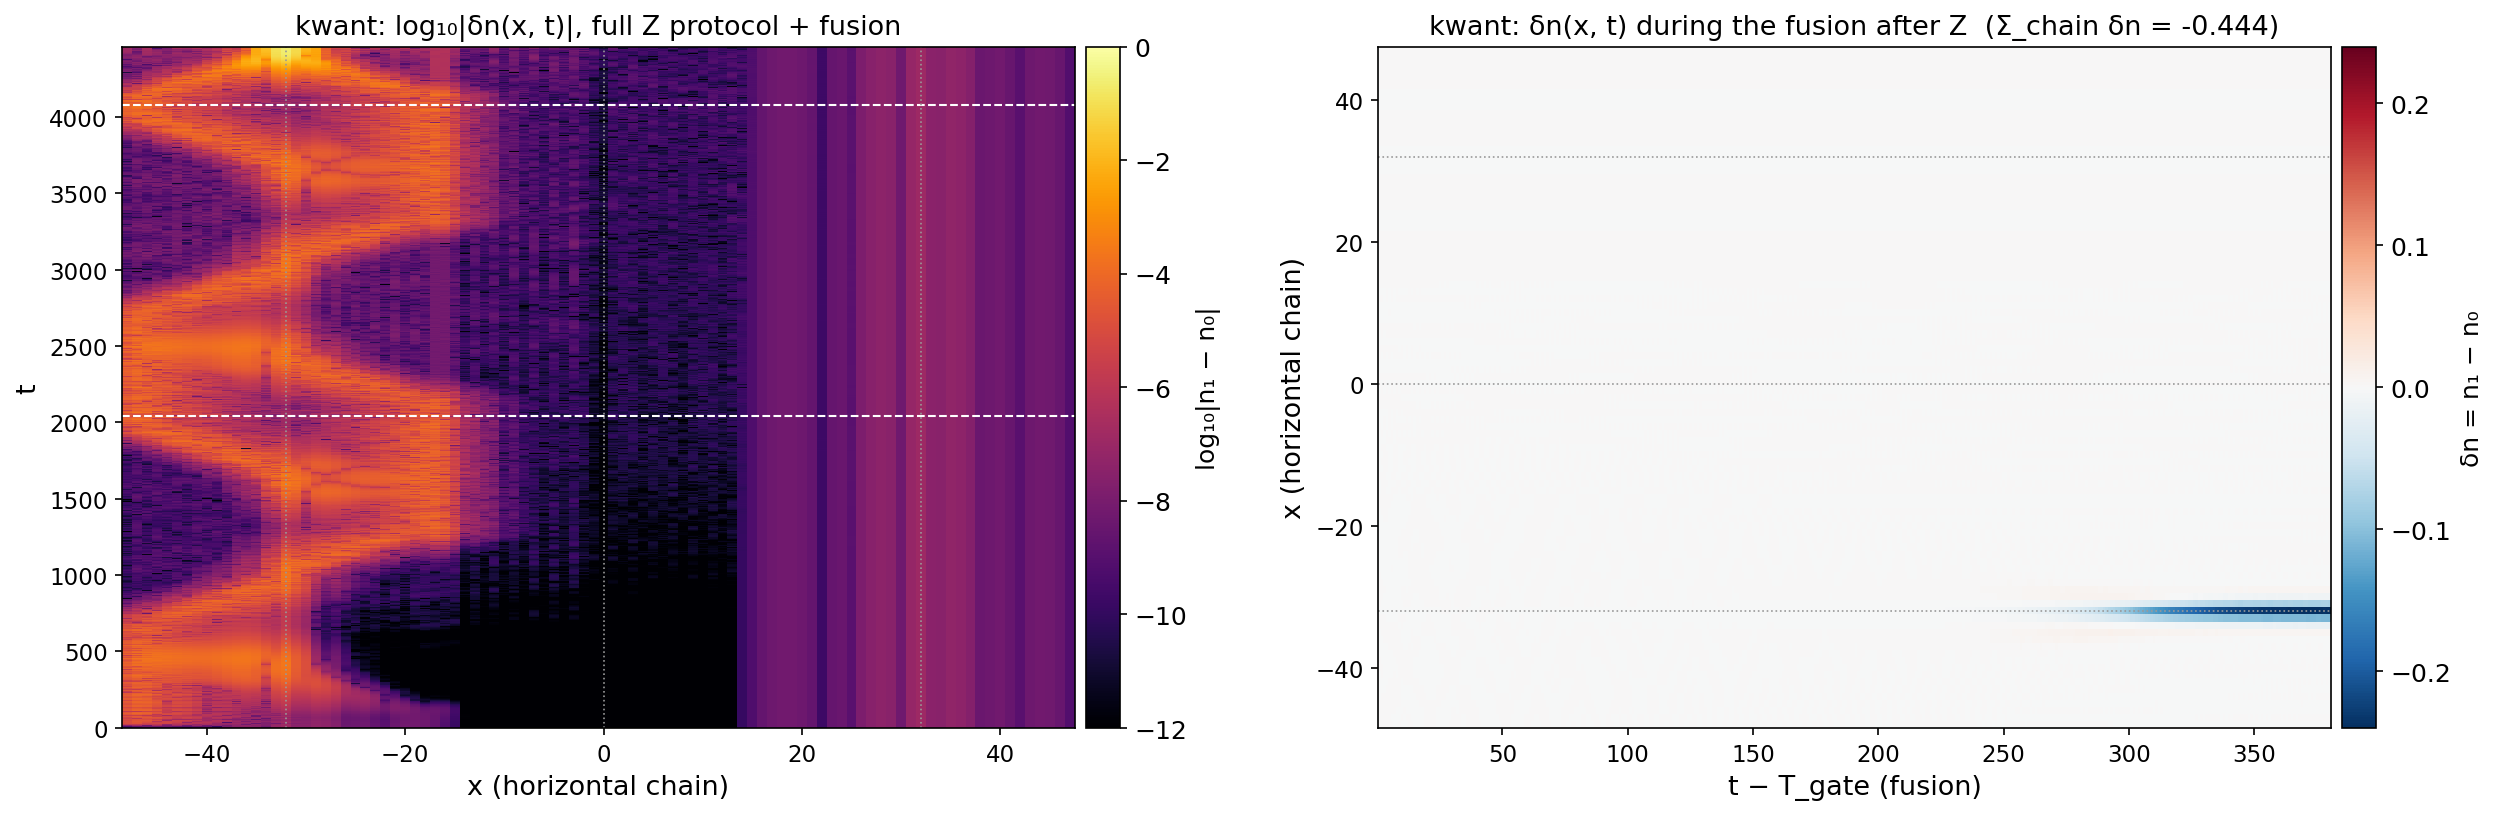

X (rot_Tx = 400): T_gate = 7760, 1933 snapshots, ΔQ(T) = +0.477004


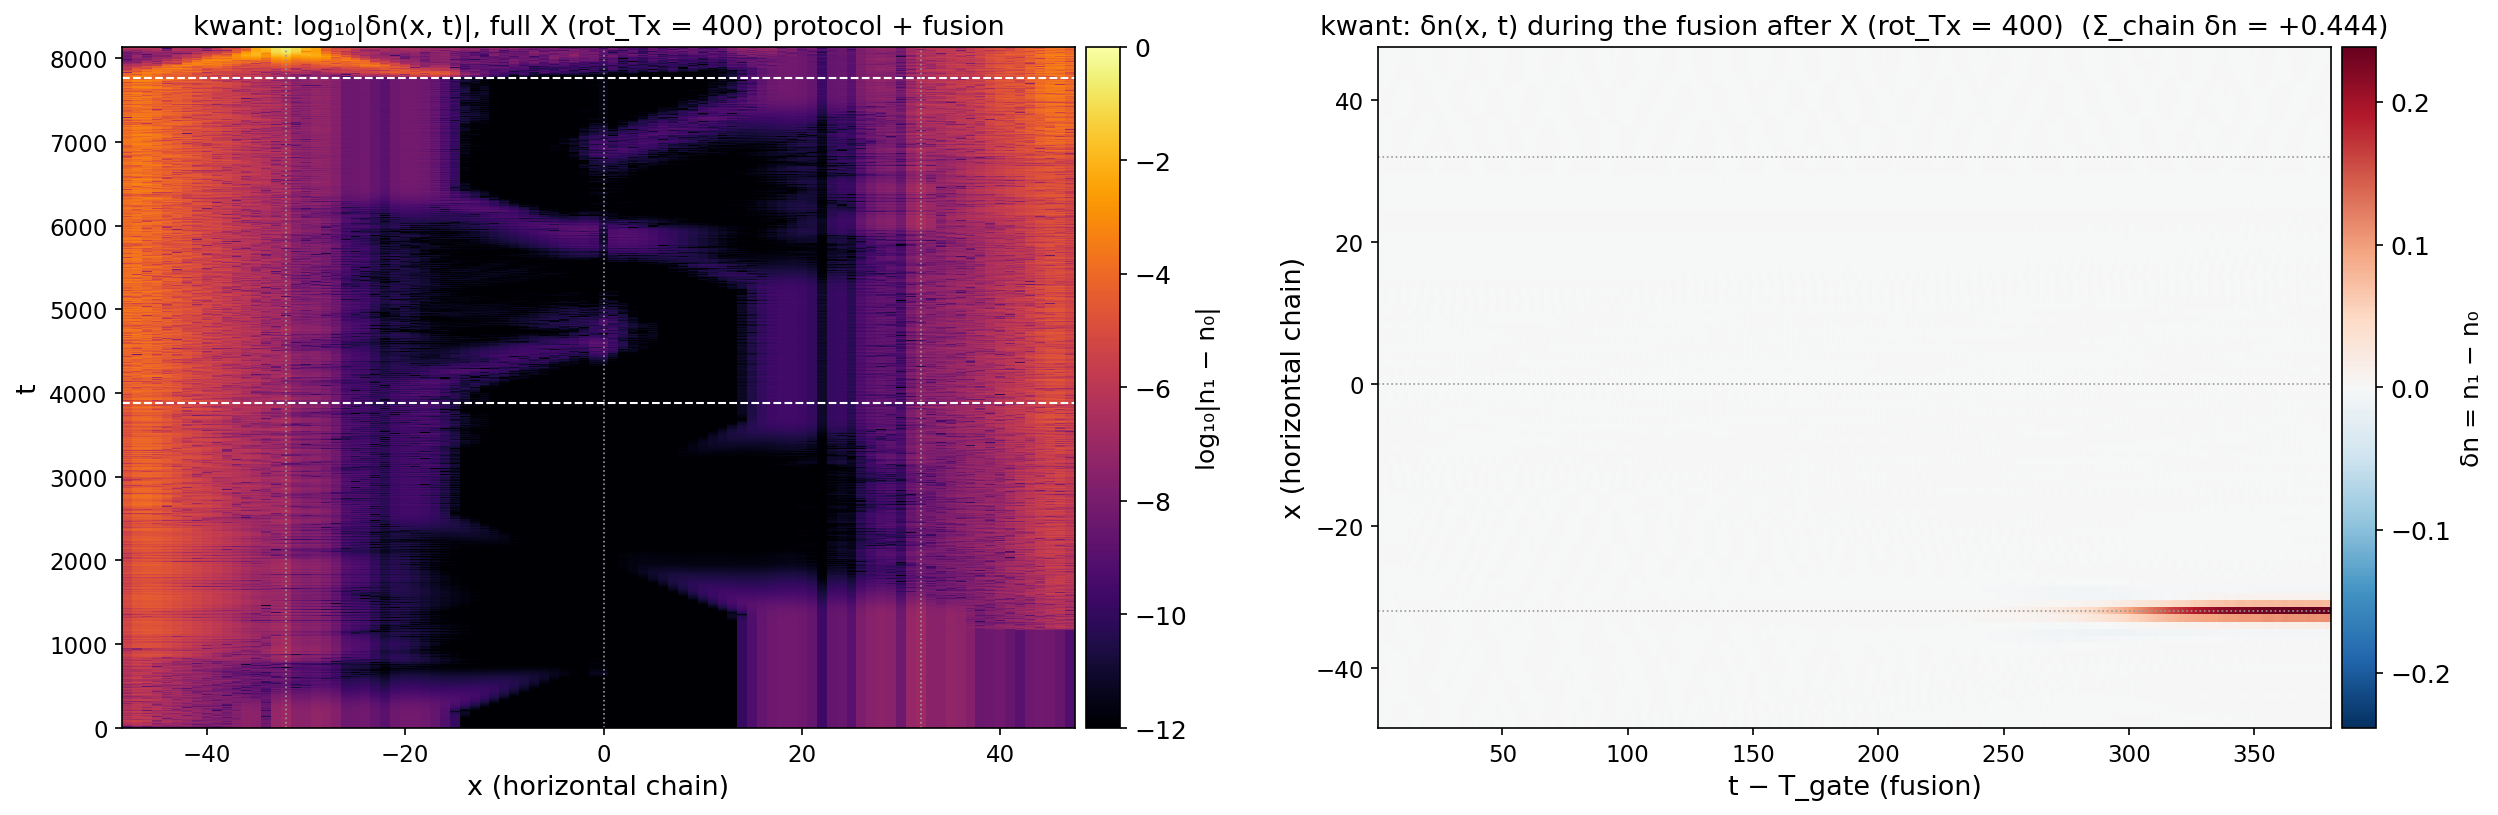

In [12]:
def density_figure(ts, x, D, Tg, gate, method, out):
    fig, ax = plt.subplots(1, 2, figsize=(17.04, 5.6), dpi=150)
    L = np.log10(np.maximum(np.abs(D), 1e-16))
    im0 = ax[0].pcolormesh(x, ts, L, cmap="inferno", vmin=-12, vmax=0, shading="nearest", rasterized=True)
    for yl in (Tg / 2, Tg):
        ax[0].axhline(yl, color="white", ls="--", lw=1)
    ax[0].set(xlabel="x (horizontal chain)", ylabel="t", title=f"{method}: log₁₀|δn(x, t)|, full {gate} protocol + fusion")
    fig.colorbar(im0, ax=ax[0], pad=0.01, label="log₁₀|n₁ − n₀|")
    sel = ts >= Tg
    lim = np.abs(D[sel]).max()
    im1 = ax[1].pcolormesh(ts[sel] - Tg, x, D[sel].T, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="nearest",
                           rasterized=True)
    ax[1].set(xlabel="t − T_gate (fusion)", ylabel="x (horizontal chain)",
              title=f"{method}: δn(x, t) during the fusion after {gate}  (Σ_chain δn = {D[-1].sum():+.3f})")
    fig.colorbar(im1, ax=ax[1], pad=0.01, label="δn = n₁ − n₀")
    for xc_ in (center_x(c) for c in range(1, NCELL + 1)):
        ax[0].axvline(xc_, color="0.6", lw=0.8, ls=":")
        ax[1].axhline(xc_, color="0.6", lw=0.8, ls=":")
    for a_ in ax:
        a_.title.set_size(13); a_.xaxis.label.set_size(13); a_.yaxis.label.set_size(13); a_.tick_params(labelsize=11)
    fig.tight_layout(); fig.savefig(out); plt.show(); plt.close(fig)

DN = {}
for key, gate, r in (("Z", "Z", rZ), ("X400", "X (rot_Tx = 400)", rX)):
    ts, D, dQ = r["snap"]; Tg = r["Tg"]
    DN[key] = (ts, D, Tg)
    np.savez(os.path.join(DATA_DIR, f"gate_density_kwant_{key}.npz"), ts=ts, x=xs[hz], D=D, Tg=Tg, dQ=dQ)   # ΔQ(t) over all sites
    print(f"{gate}: T_gate = {Tg:.0f}, {len(ts)} snapshots, ΔQ(T) = {dQ[-1]:+.6f}")
    density_figure(ts, xs[hz], D, Tg, gate, "kwant", os.path.join(DATA_DIR, f"gate_density_kwant_{key}.png"))

## 10. Save the leakage and fusion results

The leakage and fusion results under the same keys as `msh_tjunctions_tn_gates.csv` (written by `msh_tjunctions_tn.ipynb`), saved to
`DATA_DIR/gates_kwant.npz` for `tjunctions_compare.ipynb`. The fusion leakage is measured against the four lowest states of $H$ at the end of
the fusion, and the adiabatic $\Delta Q$ is that of the $+E_A$ state of pair A.

In [13]:
iA = np.argsort(np.abs(E_end))[:4][np.argmax(E_end[np.argsort(np.abs(E_end))[:4]])]     # +E_A at the end of the fusion
gates = dict(Z_leak_A=rZ["leak"][0], Z_leak_B=rZ["leak"][1], X_leak_A=rX["leak"][0], X_leak_B=rX["leak"][1],
             Z_fus_dQ=rZ["fusion"]["dQ"], X_fus_dQ=rX["fusion"]["dQ"], F_fus_dQ=rF["fusion"]["dQ"],
             Z_fus_leak_A=rZ["fusion"]["leak"][0], X_fus_leak_A=rX["fusion"]["leak"][0], F_fus_leak_A=rF["fusion"]["leak"][0],
             fus_dQad_A=np.real(np.vdot(U_end[:, iA], tauz * U_end[:, iA])), fus_E_A=E_end[iA])
for k, v in gates.items():
    print(f"{k:14s} {v:+.6g}")
np.savez(os.path.join(DATA_DIR, "gates_kwant.npz"), **gates)

Z_leak_A       +1.99727e-06
Z_leak_B       -1.33227e-15
X_leak_A       +3.41631e-05
X_leak_B       +3.48691e-05
Z_fus_dQ       -0.477717
X_fus_dQ       +0.477004
F_fus_dQ       -0.477373
Z_fus_leak_A   +3.6963e-05
X_fus_leak_A   +8.0751e-05
F_fus_leak_A   +3.77783e-05
fus_dQad_A     -0.476854
fus_E_A        +0.0438539


## 11. Cost of the dense route

**Measured times.** Wall time of each evolution above (the full $4N \times 4N$ basis, sparse Gauss–Legendre steps with $dt = 0.25$, one thread),
with the number of steps and the time per step, and the time of one full diagonalization of $H$.

**Scaling.** One step of the full basis (the two stage matrices, the sparse LU and the solve) and one full diagonalization are
timed for arms of 16, 32 and 64 sites (144, 288, 576 sites; $D$ = 576, 1152, 2304) with the initial texture.

**Benchmark vs measured step.** At 144 sites the benchmark step (~25 ms) is shorter than the measured step of the runs (~35 ms) because
`bench_step` uses a static $H$ and times only the step arithmetic. A step of `evolve` also rebuilds the sparse $H(t)$ at both Gauss points
(`ham_sp`), goes through the thread-pool solve (which copies $B$ into contiguous chunks and stacks the result, even with one thread),
and normalizes $\psi$; the readout adds a little every few steps. Timed one at a time, these account for the difference (roughly 5, 7 and 1 ms
per step on this machine). The benchmark measures how the step arithmetic itself scales with $D$; the extra work is overhead of this implementation, not of the method. Everything is written to
`DATA_DIR/timing_kwant.npz` for `tjunctions_compare.ipynb`.

In [14]:
steps = {"Z_gate": 2 * T12, "Z_fusion": Tf, "F_fusion": Tf, "X400_gate": 2 * T23, "X400_fusion": Tf}
print(f"{'':16s} {'wall time':>10s} {'steps':>8s} {'per step':>10s}   (dt = {DT})")
for k, T in steps.items():
    n = int(round(T / DT))
    print(f"{k:16s} {TIMES[k]:9.1f}s {n:8d} {1e3 * TIMES[k] / n:8.2f} ms")
t_ = time.perf_counter(); la.eigh(H0); t_eigh = time.perf_counter() - t_
print(f"eigh of H (D = {4 * N}): {t_eigh:.3f} s")

def ham_nleg(nleg, f=f0):
    """Dense BdG matrix of the same array with arms of `nleg` sites (texture f), and the number of sites."""
    lab = {}
    for c in range(1, NCELL + 1):
        for s in (1, 2, 3):
            for n in range(nleg):
                lab[(int((c - (NCELL + 1) / 2) * 2 * nleg) + ARM_ORIG[s-1][0] + n * ARM_DIR[s-1][0],
                     ARM_ORIG[s-1][1] + n * ARM_DIR[s-1][1])] = (c, s, n)
    S = {}
    for (x, y), (c, s, n) in lab.items():
        th = (-1) ** (x + y) * (np.pi / 2) * f(c, s, n); ph = ARM_ANG[s-1] + np.pi / 2
        S[(x, y)] = (np.cos(ph) * np.sin(th), np.sin(ph) * np.sin(th), np.cos(th))
    def chain(site, mu, Delta, J, S):
        Sx, Sy, Sz = S[site.tag]
        return -mu * tzs0 + Delta * txs0 + J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)
    hop_x = lambda si, sj, t, alpha: -t * tzs0 + 1j * alpha * tzsy
    hop_y = lambda si, sj, t, alpha: -t * tzs0 - 1j * alpha * tzsx
    b = kwant.Builder(); lat = kwant.lattice.square(norbs=4)
    for xy in lab:
        b[lat(*xy)] = chain
    for delta, hop in zip([(1, 0), (0, 1)], [hop_x, hop_y]):
        b[kwant.HoppingKind(delta, lat)] = hop
    fs = b.finalized()
    return fs.hamiltonian_submatrix(params={**params, "S": S}, sparse=True).tocsc(), len(lab)

def bench_step(H, dt=DT, nst=3):
    """Time of one full-basis Gauss–Legendre step (sparse LU) with a static H, as in `step`."""
    D = H.shape[0]; I_ = sp.identity(D, dtype=complex, format="csc"); psi = np.eye(D, dtype=complex)
    t_ = time.perf_counter()
    for _ in range(nst):
        M0 = -1j * (H + 0 * H).tocsc(); M1 = -1j * (H + 0 * H).tocsc()
        A = sp.bmat([[I_ - 0.25*dt*M0, -a12*dt*M0], [-a21*dt*M1, I_ - 0.25*dt*M1]], format="csc")
        K = splu(A, permc_spec="MMD_AT_PLUS_A").solve(np.vstack([M0 @ psi, M1 @ psi])).reshape(2, D, D)
        psi = psi + 0.5*dt*(K[0] + K[1])
    return (time.perf_counter() - t_) / nst

bench = []
for nleg in (16, 32, 64):
    H, nsite = ham_nleg(nleg)
    D = H.shape[0]
    t_step = bench_step(H)
    t_ = time.perf_counter(); la.eigh(H.toarray()); t_e = time.perf_counter() - t_
    bench.append((nleg, nsite, D, t_step, t_e))
    print(f"arms of {nleg:2d} sites: {nsite:4d} sites, D = {D:5d}:  full-basis step {1e3 * t_step:9.1f} ms,  eigh {t_e:7.3f} s")

np.savez(os.path.join(DATA_DIR, "timing_kwant.npz"), **{f"time_{k}": v for k, v in TIMES.items()},
         **{f"steps_{k}": int(round(T / DT)) for k, T in steps.items()}, dt=DT, eigh=t_eigh,
         bench_nleg=[b[0] for b in bench], bench_sites=[b[1] for b in bench], bench_D=[b[2] for b in bench],
         bench_step=[b[3] for b in bench], bench_eigh=[b[4] for b in bench])

                  wall time    steps   per step   (dt = 0.25)
Z_gate               570.6s    16320    34.96 ms
Z_fusion              54.4s     1520    35.76 ms
F_fusion              54.0s     1520    35.56 ms
X400_gate           1110.0s    31040    35.76 ms
X400_fusion           54.1s     1520    35.57 ms
eigh of H (D = 576): 0.078 s
arms of 16 sites:  144 sites, D =   576:  full-basis step      24.6 ms,  eigh   0.078 s
arms of 32 sites:  288 sites, D =  1152:  full-basis step     157.6 ms,  eigh   0.544 s
arms of 64 sites:  576 sites, D =  2304:  full-basis step    1095.3 ms,  eigh   5.649 s
